# バンドパスフィルタ(多重帰還)

ある周波数のまわり(**帯域**)だけを通し、それより低い周波数も高い周波数も落とす回路です。たくさんの周波数が混ざった信号から、ほしい周波数だけを取り出すのに使います(例:ラジオの選局、特定の音の検出)。

この回では、Q と帯域幅の関係を測り、方形波の中から特定の周波数の正弦波を取り出します。

## 回路

![多重帰還のバンドパスフィルタ](03_mfb_bpf/circuit.svg)

出力から 2 つの経路(C2 と R3)で戻しているので、**多重帰還**(MFB:Multiple Feedback)と呼びます。オペアンプの + 入力は信号のグランド(Mimic の Vref)につなぎます。C1 と C2 は同じ値 C にします。この回路は**反転**します(出力の向きが入力と逆)。

## 原理

C1 は低い周波数を通さず(HPF の働き)、C2 は高い周波数で出力を入力側へ強く戻して利得を下げます(LPF の働き)。両方が働かない中ほどの周波数だけが通ります。

Mimic のバンドパスフィルタは、中心周波数 $f_c$ でゲインが 1 になる形です。

$$H(f) = \frac{j\,\dfrac{f/f_c}{Q}}{1 - (f/f_c)^2 + j\,\dfrac{f/f_c}{Q}}$$

| 周波数 | 振幅 | 位相 |
|---|---|---|
| $f \ll f_c$ | 小さい(+20 dB/dec) | +90° に近づく |
| $f = f_c$ | 1 | 0° |
| $f \gg f_c$ | 小さい(−20 dB/dec) | −90° に近づく |

ゲインが $1/\sqrt{2}$(−3 dB)以上になる周波数の幅を**帯域幅** $B$ といい、

$$B = \frac{f_c}{Q}$$

です。Q が大きいほど、狭い範囲だけを鋭く選びます。

![2 次の BPF の周波数特性(模式図)](03_mfb_bpf/response.svg)

## Mimic の設定と回路定数

| Mimic(Python) | ライブラリ(Arduino) | 回路(C1 = C2 = C) |
|---|---|---|
| `lab.mimic.biquad_bpf(fc, q)` | `mimic.setFilterBiquadBPF(fc, Q)` | $f_c = \dfrac{1}{2\pi C}\sqrt{\dfrac{R_1 + R_2}{R_1 R_2 R_3}}$、$Q = \pi f_c R_3 C$、中心のゲイン $= -\dfrac{R_3}{2 R_1}$ |

例:$f_c$ = 100 Hz、Q = 5、中心のゲイン −1 は、C = 100 nF、R3 = 159 kΩ、R1 = 80 kΩ、R2 = 1.6 kΩ の回路にあたります。

回路は反転しますが、Mimic のバンドパスフィルタは反転しません($f_c$ で位相 0°)。

## 準備:測定器につなぐ

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mimiclab import MimicLab, Monitor, fit_sine, match_phase, plot_waveforms

lab = MimicLab()  # finds the Arduino; or MimicLab("COM5")
lab

MimicLab(port='COM4', ver=0.1.0, mimic=20261123)

In [2]:
FC = 100  # centre frequency [Hz]

def bode_axes(title):
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
    ax1.set_title(title)
    ax1.set_ylabel("Gain [dB]")
    ax2.set_ylabel("Phase [deg]")
    ax2.set_xlabel("Frequency [Hz]")
    for ax in (ax1, ax2):
        ax.grid(True, which="both", alpha=0.4)
    return fig, ax1, ax2


def second_order(f, fc, q, kind):
    # Response of the module: lpf 1/D, hpf s^2/D, bpf (s/Q)/D, notch (s^2 + 1)/D
    s = 1j * f / fc
    d = s * s + s / q + 1
    return {"lpf": 1, "hpf": s * s, "bpf": s / q, "notch": s * s + 1}[kind] / d

## 実験 1:Q と帯域幅

Q = 1 と 5 で、$f_c$ のまわりを細かく測ります。ゲインが 0.707 になる 2 つの周波数を補間で求め、その差(帯域幅)を $f_c / Q$ と比べます。

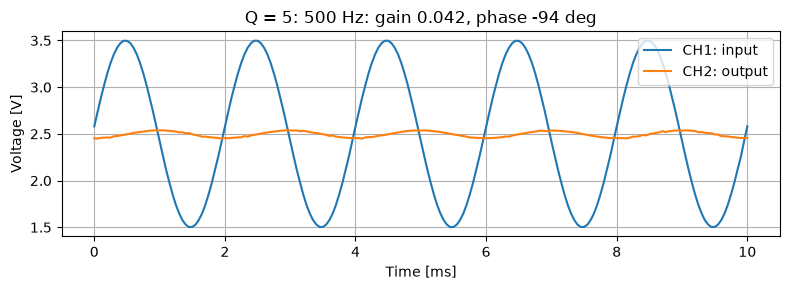

Q = 1: -3 dB at 62.0 and 162.5 Hz, bandwidth 100.5 Hz (theory 100.0)
Q = 5: -3 dB at 90.9 and 110.6 Hz, bandwidth 19.6 Hz (theory 20.0)


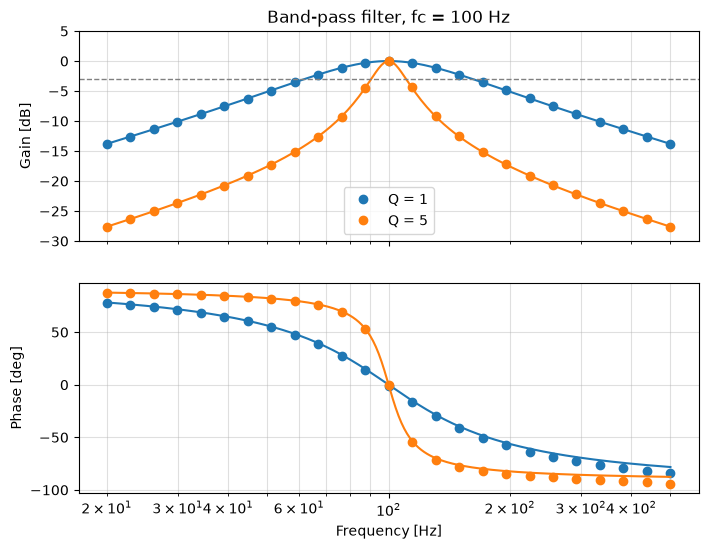

In [3]:
freqs = np.logspace(np.log10(20), np.log10(500), 25)   # 20 - 500 Hz
f_th = np.logspace(np.log10(20), np.log10(500), 200)
fig, ax1, ax2 = bode_axes(f"Band-pass filter, fc = {FC} Hz")
rs = {}
mon = Monitor()  # one plot updated while measuring
for i, q in enumerate([1, 5]):
    lab.mimic.biquad_bpf(FC, q)
    r = rs[q] = lab.frequency_response(freqs, monitor=mon, label=f"Q = {q}: ")
    h = second_order(f_th, FC, q, "bpf")
    ax1.semilogx(f_th, 20 * np.log10(abs(h)), "-", color=f"C{i}")
    ax2.semilogx(f_th, np.degrees(np.angle(h)), "-", color=f"C{i}")
    ax1.semilogx(r.freq, r.gain_db, "o", color=f"C{i}", label=f"Q = {q}")
    ax2.semilogx(r.freq, match_phase(r.phase, np.degrees(np.unwrap(np.angle(second_order(r.freq, FC, q, "bpf"))))), "o", color=f"C{i}")
    # -3 dB points: where the gain crosses 0.707 below and above fc
    k = int(np.argmax(r.gain))
    lo = np.interp(0.707, r.gain[:k + 1], r.freq[:k + 1])
    hi = np.interp(0.707, r.gain[k:][::-1], r.freq[k:][::-1])
    print(f"Q = {q}: -3 dB at {lo:.1f} and {hi:.1f} Hz, bandwidth {hi - lo:.1f} Hz (theory {FC / q:.1f})")
ax1.axhline(-3, color="gray", ls="--", lw=1)
ax1.set_ylim(-30, 5)
ax1.legend()
mon.close()
plt.show()

各周波数で取り込んだ波形です(クリックで開きます)。


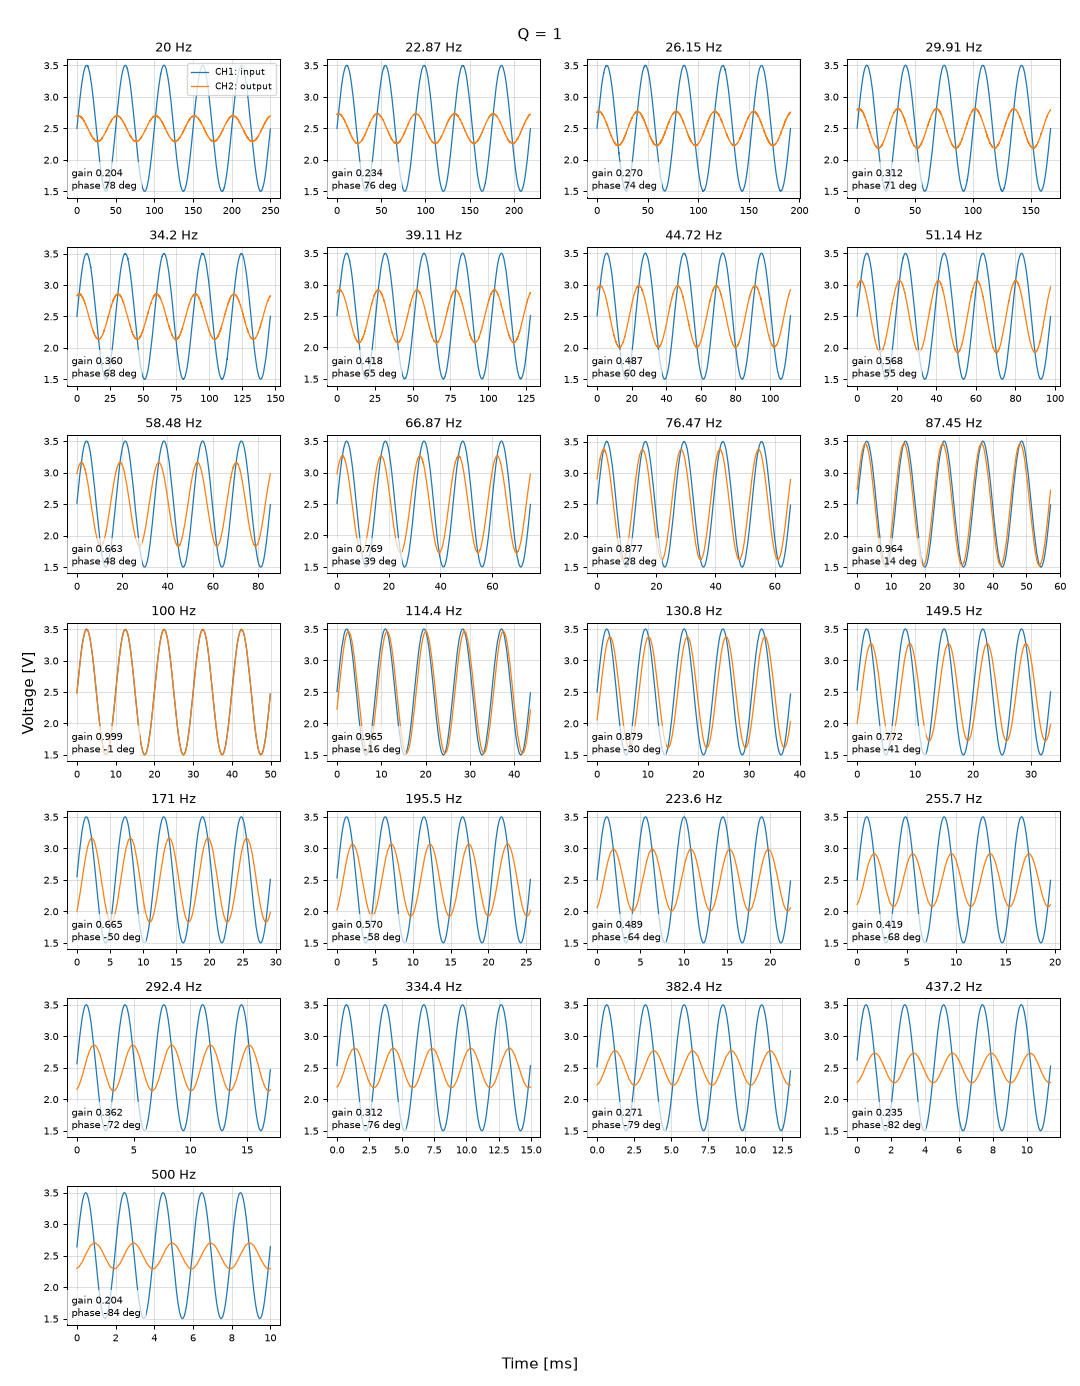


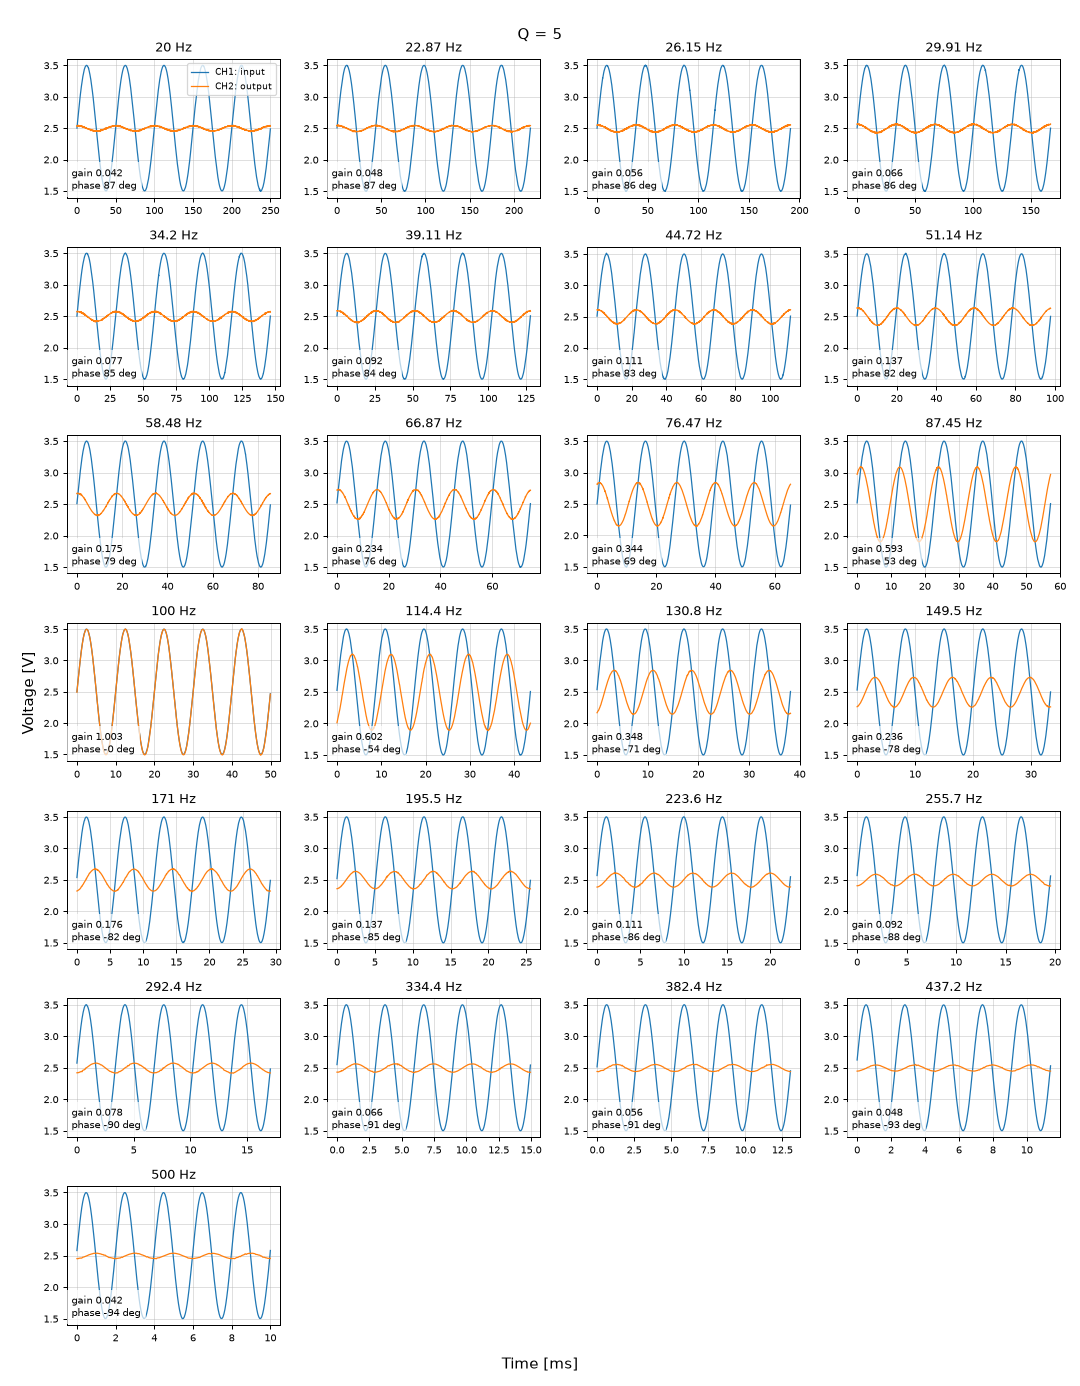

In [4]:
for key, r in rs.items():
    plot_waveforms(r, title=f"Q = {key}", collapsed=True)

## 実験 2:方形波から正弦波を取り出す

方形波は、基本の周波数 $f$ と、その奇数倍($3f$、$5f$、…)の正弦波を重ね合わせたものです。振幅 $A$ の方形波に含まれる成分の振幅は

$$\frac{4A}{\pi},\ \frac{4A}{3\pi},\ \frac{4A}{5\pi},\ \dots$$

です(偶数倍は含みません)。100 Hz の方形波を、Q = 10 のバンドパスフィルタに入れて、中心周波数を 100 Hz、200 Hz、300 Hz にしてみます。

fc = 100 Hz: amplitude 0.636 V (theory 0.637 V)
fc = 200 Hz: amplitude 0.000 V (theory 0.000 V)
fc = 300 Hz: amplitude 0.213 V (theory 0.212 V)


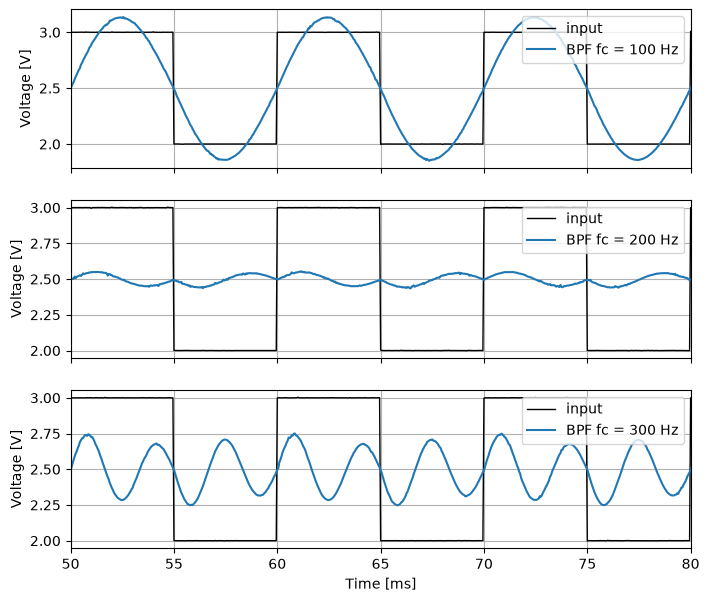

In [5]:
import time

A = 0.5
lab.fg.square(100, A)
fig, axes = plt.subplots(3, 1, figsize=(8, 7), sharex=True)
for ax, n in zip(axes, [1, 2, 3]):
    fc = 100 * n
    lab.mimic.biquad_bpf(fc, 10)
    time.sleep(0.3)  # wait for the filter to settle (Q = 10 rings for a while)
    t, ch1, ch2 = lab.scope.capture(2000)  # 0.1 s
    amp, ph, c = fit_sine(t[1000:], ch2[1000:], fc)  # the second half: settled
    theory = 4 * A / (np.pi * n) if n % 2 else 0.0
    print(f"fc = {fc} Hz: amplitude {amp:.3f} V (theory {theory:.3f} V)")
    ax.plot(t * 1e3, ch1, "k", lw=1, label="input")
    ax.plot(t * 1e3, ch2, label=f"BPF fc = {fc} Hz")
    ax.set_ylabel("Voltage [V]")
    ax.grid(True)
    ax.legend(loc="upper right")
axes[-1].set_xlabel("Time [ms]")
axes[-1].set_xlim(50, 80)
plt.show()

100 Hz では大きな正弦波、300 Hz では 1/3 の大きさの正弦波が出て、200 Hz ではほとんど何も出ません。Q = 10 は帯域幅 10〜30 Hz と狭いので、隣の成分はほとんど通しません(少しは通るので、理論と少し違います)。

## やってみよう

下のセルの値(大文字の名前)を**1 つずつ**変えて実行し、オシロの波形と数値がどう変わるかを自分の目で確かめましょう。どの値を順に試すとよいかと、何が見えるはずかは「ヒント」に書いてあります。

> Run All で最後まで実行したあと(接続を閉じたあと)にやるときは、最初の「測定器につなぐ」のセルをもう一度実行してから始めます。

### 1. 何倍の成分を取り出すかを変える

100 Hz の方形波から、中心周波数を 100 Hz の何倍かにして成分を取り出します。振幅を予想してから確かめます。
<details><summary>ヒント</summary>

`N` を 1 → 3 → 5 → 7、それから 2 → 4 と変えてみましょう。奇数倍の成分の振幅は $4A/(n\pi)$ で、A = 0.5 V なら 0.637、0.212、0.127、0.091 V です。偶数倍はほとんど 0 になります。

</details>

500 Hz: amplitude 0.128 V (theory 0.127 V)


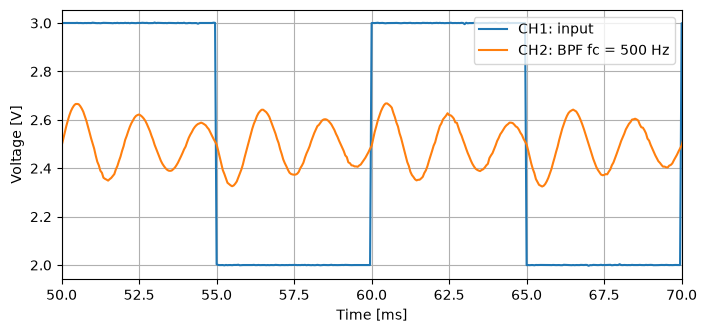

In [6]:
N = 5   # which multiple of 100 Hz

import time
A = 0.5
lab.fg.square(100, A)
lab.mimic.biquad_bpf(100 * N, 10)
time.sleep(0.3)
t, ch1, ch2 = lab.scope.capture(2000)
amp, _, _ = fit_sine(t, ch2, 100 * N)
print(f"{100 * N} Hz: amplitude {amp:.3f} V (theory {4 * A / (np.pi * N) if N % 2 else 0:.3f} V)")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label=f"CH2: BPF fc = {100 * N} Hz")
ax.set_xlim(50, 70)
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

### 2. Q を変えて、取り出した波形のきれいさを比べる

300 Hz の成分を、Q を変えて取り出します。
<details><summary>ヒント</summary>

`Q_TRY` を 10 → 5 → 2 → 1 と下げてみましょう。Q が小さいと帯域幅($f_c/Q$)が広くなり、となりの 100 Hz や 500 Hz の成分も通るので、波形がゆがみます。Q を大きくするほどきれいな正弦波になりますが、そのかわり、落ち着くまでの時間が長くなります。

</details>

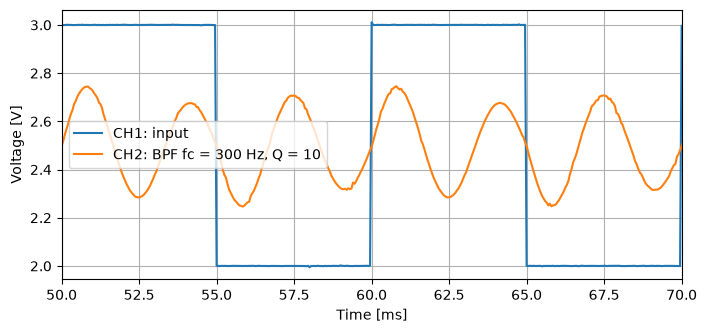

In [7]:
Q_TRY = 10

import time
lab.fg.square(100, 0.5)
lab.mimic.biquad_bpf(300, Q_TRY)
time.sleep(0.3)
t, ch1, ch2 = lab.scope.capture(2000)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label=f"CH2: BPF fc = 300 Hz, Q = {Q_TRY}")
ax.set_xlim(50, 70)
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

### 3. 三角波の成分を取り出す

三角波も、基本の周波数とその奇数倍の重ね合わせです。100 Hz の三角波から成分を取り出して、方形波のときと比べます。
<details><summary>ヒント</summary>

`N` を 1 → 3 → 5 と変えてみましょう。振幅 $A$ の三角波の成分は $\dfrac{8A}{\pi^2 n^2}$ で、$n^2$ で小さくなります(方形波は $n$)。A = 0.5 V なら 0.405、0.045、0.016 V です。三角波は角がない(なめらかな)ぶん、高い周波数の成分が少ないのです。

</details>

100 Hz: amplitude 0.406 V (theory 0.405 V)


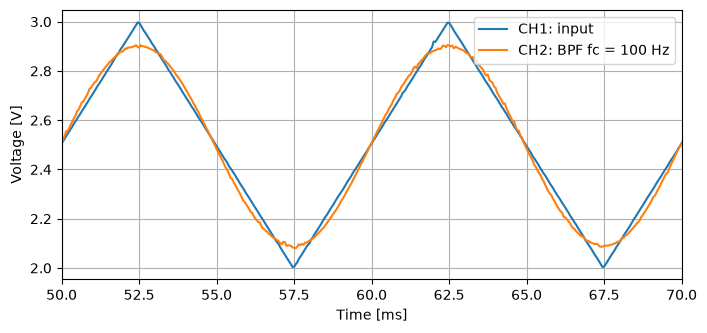

In [8]:
N = 1

import time
A = 0.5
lab.fg.triangle(100, A)
lab.mimic.biquad_bpf(100 * N, 10)
time.sleep(0.3)
t, ch1, ch2 = lab.scope.capture(2000)
amp, _, _ = fit_sine(t, ch2, 100 * N)
print(f"{100 * N} Hz: amplitude {amp:.3f} V (theory {8 * A / (np.pi ** 2 * N ** 2) if N % 2 else 0:.3f} V)")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label=f"CH2: BPF fc = {100 * N} Hz")
ax.set_xlim(50, 70)
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

## まとめ

- バンドパスフィルタは $f_c$ のまわりだけを通す。帯域幅は $B = f_c / Q$。
- 方形波は基本の周波数とその奇数倍の正弦波の重ね合わせで、バンドパスフィルタでそれぞれを取り出せる。
- 多重帰還の回路は反転する。Mimic では `biquad_bpf(fc, q)`(反転しない、$f_c$ でゲイン 1)。

最後に Mimic を素通し(バイパス)に戻して、接続を閉じます。

In [9]:
lab.mimic.bypass()
lab.fg.sine(100, 1.0)
lab.close()